# Video + Audio Analysis

Independent exploratory DSP for any local video path.

1. Set `VIDEO_PATH` in the setup cell.
2. Run the setup cell once.
3. Call any function below on its own — or run the final `analyze_video_and_audio` wrapper.

**Memory tip:** for long clips use `stride>1` or `max_frames=...` in `extract_frames`.


In [3]:
# Optional bootstrap if matplotlib / jupyter are missing from the env:
# %pip install matplotlib jupyter ipykernel


In [4]:
from __future__ import annotations

import json
import sys
from pathlib import Path
from typing import Any

import cv2
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline


def _find_repo_root() -> Path:
    """Resolve repo root whether the kernel cwd is data_analysis/ or the project root."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    # Also try notebook-relative parent (when cwd is data_analysis)
    candidates = [Path.cwd() / ".."] + candidates
    for c in candidates:
        root = c.resolve()
        if (root / "Dataset" / "raw_videos").is_dir() and (root / "dataset_generating_pipepline").is_dir():
            return root
    return Path("..").resolve()


REPO_ROOT = _find_repo_root()
PIPELINE_DIR = REPO_ROOT / "dataset_generating_pipepline"
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

# Change this to any local .mp4 (or other OpenCV-readable) path.
VIDEO_PATH = REPO_ROOT / "Dataset" / "raw_videos" / "JKa05nyUmuQ" / "clip_003.mp4"

print("REPO_ROOT:", REPO_ROOT)
print("VIDEO_PATH:", VIDEO_PATH)
print("exists:", VIDEO_PATH.is_file())


REPO_ROOT: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline
VIDEO_PATH: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/JKa05nyUmuQ/clip_003.mp4
exists: True


## 0. Shared helpers

In [5]:
def probe_video(path: str | Path) -> dict[str, Any]:
    """Return fps, duration, size, frame count, and whether an audio stream exists."""
    import subprocess

    path = Path(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return {"path": str(path), "available": False}

    fps = float(cap.get(cv2.CAP_PROP_FPS) or 0.0) or 30.0
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) or 0)
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) or 0)
    duration_s = (n_frames / fps) if fps > 0 else 0.0
    cap.release()

    has_audio = False
    try:
        proc = subprocess.run(
            [
                "ffprobe", "-v", "error", "-select_streams", "a",
                "-show_entries", "stream=codec_type", "-of", "csv=p=0",
                str(path),
            ],
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            check=False,
        )
        has_audio = bool((proc.stdout or b"").strip())
    except Exception:
        has_audio = False

    return {
        "path": str(path),
        "available": True,
        "fps": fps,
        "n_frames": n_frames,
        "width": width,
        "height": height,
        "duration_s": duration_s,
        "has_audio": has_audio,
    }


def show_image(
    img: np.ndarray,
    *,
    title: str = "",
    cmap: str | None = None,
    figsize: tuple[float, float] = (8, 5),
) -> None:
    """Display an RGB or grayscale image."""
    fig, ax = plt.subplots(figsize=figsize)
    if img.ndim == 2:
        ax.imshow(img, cmap=cmap or "gray")
    else:
        ax.imshow(img, cmap=cmap) if cmap else ax.imshow(img)
    if title:
        ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


def _to_gray(frame: np.ndarray) -> np.ndarray:
    if frame.ndim == 2:
        return frame
    if frame.shape[-1] == 3:
        return cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
    return frame[..., 0]


meta = probe_video(VIDEO_PATH)
meta


{'path': '/Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/JKa05nyUmuQ/clip_003.mp4',
 'available': True,
 'fps': 24.0,
 'n_frames': 720,
 'width': 640,
 'height': 360,
 'duration_s': 30.0,
 'has_audio': True}

## 1. Video — frames

- `extract_frames` — all frames (or strided / capped)
- `show_frame_grid` — montage
- `average_frame` — mean pixel image + intensity
- `pixel_intensity_stats` — per-frame / global intensity


In [6]:
def extract_frames(
    path: str | Path,
    *,
    stride: int = 1,
    max_frames: int | None = None,
    gray: bool = False,
    analysis_width: int | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Load frames from a video.

    Returns
    -------
    frames : (N, H, W) uint8 if gray else (N, H, W, 3) RGB
    timestamps_s : (N,) float64
    """
    path = Path(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise FileNotFoundError(f"Cannot open video: {path}")

    fps = float(cap.get(cv2.CAP_PROP_FPS) or 0.0) or 30.0
    frames: list[np.ndarray] = []
    timestamps: list[float] = []
    idx = 0
    kept = 0

    while True:
        ok, bgr = cap.read()
        if not ok:
            break
        if idx % stride != 0:
            idx += 1
            continue

        if analysis_width is not None and analysis_width > 0:
            h, w = bgr.shape[:2]
            new_h = max(1, int(h * analysis_width / max(w, 1)))
            bgr = cv2.resize(bgr, (analysis_width, new_h))

        if gray:
            frame = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        else:
            frame = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

        frames.append(frame)
        timestamps.append(idx / fps)
        kept += 1
        idx += 1
        if max_frames is not None and kept >= max_frames:
            break

    cap.release()
    if not frames:
        raise RuntimeError(f"No frames decoded from {path}")

    return np.stack(frames, axis=0), np.asarray(timestamps, dtype=np.float64)


def show_frame_grid(
    frames: np.ndarray,
    n: int = 12,
    *,
    timestamps_s: np.ndarray | None = None,
    figsize: tuple[float, float] | None = None,
) -> None:
    """Show evenly spaced sample frames across the clip."""
    n = min(n, len(frames))
    idxs = np.linspace(0, len(frames) - 1, n, dtype=int)
    cols = min(4, n)
    rows = int(np.ceil(n / cols))
    figsize = figsize or (4 * cols, 3 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, idxs):
        img = frames[i]
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(img)
        title = f"#{i}"
        if timestamps_s is not None:
            title += f"  {timestamps_s[i]:.2f}s"
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def average_frame(frames: np.ndarray) -> tuple[np.ndarray, float]:
    """Mean over all frames → image (uint8) + scalar mean intensity."""
    avg = frames.astype(np.float64).mean(axis=0)
    intensity = float(avg.mean())
    out = np.clip(avg, 0, 255).astype(np.uint8)
    return out, intensity


def pixel_intensity_stats(
    frames: np.ndarray,
    *,
    timestamps_s: np.ndarray | None = None,
    plot: bool = True,
) -> dict[str, Any]:
    """Per-frame mean/std intensity and global aggregates."""
    flat = frames.reshape(len(frames), -1).astype(np.float64)
    per_mean = flat.mean(axis=1)
    per_std = flat.std(axis=1)
    t = timestamps_s if timestamps_s is not None else np.arange(len(frames))

    stats = {
        "per_frame_mean": per_mean,
        "per_frame_std": per_std,
        "global_mean": float(per_mean.mean()),
        "global_min": float(per_mean.min()),
        "global_max": float(per_mean.max()),
        "global_std": float(per_mean.std()),
        "argmax_frame": int(np.argmax(per_mean)),
        "argmin_frame": int(np.argmin(per_mean)),
    }

    if plot:
        fig, ax = plt.subplots(figsize=(14, 3))
        ax.plot(t, per_mean, lw=1.0, label="mean intensity")
        ax.fill_between(t, per_mean - per_std, per_mean + per_std, alpha=0.2, label="±1 std")
        ax.set_xlabel("time (s)" if timestamps_s is not None else "frame")
        ax.set_ylabel("pixel intensity")
        ax.set_title("Per-frame pixel intensity")
        ax.legend(loc="upper right")
        # Tick every 1s (or every frame) so each second is readable
        t_min, t_max = float(np.min(t)), float(np.max(t))
        if timestamps_s is not None:
            ax.set_xticks(np.arange(np.floor(t_min), np.ceil(t_max) + 1, 1))
            ax.tick_params(axis="x", labelsize=8, rotation=45)
        else:
            step = max(1, int(round((t_max - t_min) / 30)))
            ax.set_xticks(np.arange(int(np.floor(t_min)), int(np.ceil(t_max)) + 1, step))
        ax.set_xlim(t_min, t_max)
        plt.tight_layout()
        plt.show()

    return stats


def intensity_extrema(
    per_mean: np.ndarray,
    *,
    timestamps_s: np.ndarray | None = None,
    per_std: np.ndarray | None = None,
    prominence: float | None = None,
    distance: int = 8,
    change_threshold: float | None = None,
    min_change: float = 0.5,
    plot: bool = True,
) -> dict[str, Any]:
    """Local max/min + sudden intensity changes.

    - Extrema: peaks / troughs on the mean-intensity curve.
    - Sudden changes: contiguous runs where |Δ intensity| exceeds a low
      threshold (small jumps included). Reports start/end and mean time.

    Full timings are printed in separate tables. The plot uses numbered
    markers (E# / C#) so close events do not overlap with time text.
    """
    from scipy.signal import find_peaks

    y = np.asarray(per_mean, dtype=np.float64)
    t = timestamps_s if timestamps_s is not None else np.arange(len(y), dtype=np.float64)
    if prominence is None:
        prominence = max(2.0, float(np.std(y) * 0.35))

    peak_idx, _ = find_peaks(y, prominence=prominence, distance=distance)
    trough_idx, _ = find_peaks(-y, prominence=prominence, distance=distance)

    peaks = [
        {"id": None, "frame": int(i), "time_s": float(t[i]), "intensity": float(y[i]), "kind": "max"}
        for i in peak_idx
    ]
    troughs = [
        {"id": None, "frame": int(i), "time_s": float(t[i]), "intensity": float(y[i]), "kind": "min"}
        for i in trough_idx
    ]
    extrema = sorted(peaks + troughs, key=lambda e: e["time_s"])
    for n, e in enumerate(extrema, 1):
        e["id"] = n

    # --- sudden changes from frame-to-frame diffs ---
    dy = np.diff(y)
    abs_dy = np.abs(dy)
    if change_threshold is None:
        # Sensitive: catch small jumps, not only large cuts
        change_threshold = max(min_change, float(np.percentile(abs_dy, 70)) if len(abs_dy) else min_change)
    change_threshold = float(max(min_change, change_threshold))

    changes: list[dict[str, Any]] = []
    i = 0
    while i < len(dy):
        if abs_dy[i] < change_threshold:
            i += 1
            continue
        j = i
        while j + 1 < len(dy) and abs_dy[j + 1] >= change_threshold:
            j += 1
        # change spans samples i..j (diffs between frames i→i+1 .. j→j+1)
        start_f, end_f = int(i), int(j + 1)
        start_s, end_s = float(t[start_f]), float(t[end_f])
        mean_s = 0.5 * (start_s + end_s)
        delta = float(y[end_f] - y[start_f])
        changes.append({
            "id": None,
            "start_frame": start_f,
            "end_frame": end_f,
            "start_s": start_s,
            "end_s": end_s,
            "mean_time_s": mean_s,
            "duration_s": end_s - start_s,
            "delta": delta,
            "abs_delta": abs(delta),
            "direction": "up" if delta >= 0 else "down",
            "intensity_before": float(y[start_f]),
            "intensity_after": float(y[end_f]),
        })
        i = j + 1
    for n, c in enumerate(changes, 1):
        c["id"] = n

    result = {
        "n_peaks": len(peaks),
        "n_troughs": len(troughs),
        "n_extrema": len(extrema),
        "n_changes": len(changes),
        "prominence": float(prominence),
        "distance": int(distance),
        "change_threshold": change_threshold,
        "peaks": peaks,
        "troughs": troughs,
        "extrema": extrema,
        "changes": changes,
        "peak_times_s": [e["time_s"] for e in peaks],
        "trough_times_s": [e["time_s"] for e in troughs],
        "change_mean_times_s": [c["mean_time_s"] for c in changes],
    }

    # ---- separate printed tables (no overlap) ----
    print("=" * 72)
    print(f"EXTREMA  peaks={result['n_peaks']}  troughs={result['n_troughs']}  "
          f"(prominence≥{prominence:.2f}, distance≥{distance})")
    print("=" * 72)
    if not extrema:
        print("(none)")
    else:
        print(f"{'E#':>3}  {'kind':<4}  {'time_s':>8}  {'frame':>6}  {'intensity':>10}")
        for e in extrema:
            print(f"{e['id']:>3}  {e['kind']:<4}  {e['time_s']:8.3f}  {e['frame']:6d}  {e['intensity']:10.3f}")

    print()
    print("=" * 72)
    print(f"SUDDEN CHANGES  n={result['n_changes']}  "
          f"(|Δ|≥{change_threshold:.2f} intensity units)")
    print("=" * 72)
    if not changes:
        print("(none — lower change_threshold / min_change if needed)")
    else:
        print(f"{'C#':>3}  {'dir':<4}  {'mean_s':>8}  {'start_s':>8}  {'end_s':>8}  "
              f"{'Δ':>8}  {'before':>8}  {'after':>8}")
        for c in changes:
            print(f"{c['id']:>3}  {c['direction']:<4}  {c['mean_time_s']:8.3f}  "
                  f"{c['start_s']:8.3f}  {c['end_s']:8.3f}  {c['delta']:8.2f}  "
                  f"{c['intensity_before']:8.2f}  {c['intensity_after']:8.2f}")

    if plot:
        fig, (ax, ax_d) = plt.subplots(
            2, 1, figsize=(14, 6.2), sharex=True,
            gridspec_kw={"height_ratios": [2.4, 1.0]},
        )

        # Top: intensity + numbered extrema / change markers
        ax.plot(t, y, lw=1.0, color="C0", label="mean intensity")
        if per_std is not None:
            ax.fill_between(t, y - per_std, y + per_std, alpha=0.15, color="C0", label="±1 std")

        if len(peak_idx):
            ax.scatter(t[peak_idx], y[peak_idx], c="crimson", s=40, zorder=5,
                       marker="^", label=f"peaks ({len(peak_idx)})")
        if len(trough_idx):
            ax.scatter(t[trough_idx], y[trough_idx], c="darkorange", s=40, zorder=5,
                       marker="v", label=f"troughs ({len(trough_idx)})")

        # Number-only labels, alternating offsets to reduce overlap
        for k, e in enumerate(extrema):
            dy_off = 10 if (k % 2 == 0) else 20
            if e["kind"] == "min":
                dy_off = -dy_off
            ax.annotate(
                f"E{e['id']}", (e["time_s"], e["intensity"]),
                textcoords="offset points", xytext=(0, dy_off),
                ha="center", fontsize=7, color="crimson" if e["kind"] == "max" else "darkorange",
                fontweight="bold",
            )

        y_lo, y_hi = float(np.min(y)), float(np.max(y))
        y_span = max(y_hi - y_lo, 1.0)
        for k, c in enumerate(changes):
            color = "#2ca02c" if c["direction"] == "up" else "#9467bd"
            ax.axvspan(c["start_s"], c["end_s"], color=color, alpha=0.12, zorder=0)
            ax.axvline(c["mean_time_s"], color=color, ls="--", lw=0.9, alpha=0.85, zorder=3)
            # Stagger C# labels near top of axes
            y_lab = y_hi - (0.04 + 0.08 * (k % 4)) * y_span
            ax.annotate(
                f"C{c['id']}", (c["mean_time_s"], y_lab),
                ha="center", va="bottom", fontsize=7, color=color, fontweight="bold",
            )

        ax.set_ylabel("pixel intensity")
        ax.set_title("Pixel intensity — extrema (E#) + sudden changes (C#); details in printed tables")
        ax.legend(loc="upper right", fontsize=8)

        # Bottom: |Δ intensity| with change threshold
        td = 0.5 * (t[:-1] + t[1:]) if len(t) > 1 else t
        ax_d.plot(td, abs_dy, lw=0.9, color="#444444", label="|Δ intensity|")
        ax_d.axhline(change_threshold, color="red", ls=":", lw=1.0,
                     label=f"threshold={change_threshold:.2f}")
        for c in changes:
            color = "#2ca02c" if c["direction"] == "up" else "#9467bd"
            ax_d.axvline(c["mean_time_s"], color=color, ls="--", lw=0.8, alpha=0.8)
        ax_d.set_ylabel("|Δ|")
        ax_d.set_xlabel("time (s)" if timestamps_s is not None else "frame")
        ax_d.legend(loc="upper right", fontsize=8)

        t_min, t_max = float(np.min(t)), float(np.max(t))
        if timestamps_s is not None:
            ax_d.set_xticks(np.arange(np.floor(t_min), np.ceil(t_max) + 1, 1))
            ax_d.tick_params(axis="x", labelsize=8, rotation=45)
        ax.set_xlim(t_min, t_max)
        plt.tight_layout()
        plt.show()

    return result


frames shape=(720, 360, 640, 3)  duration≈29.96s


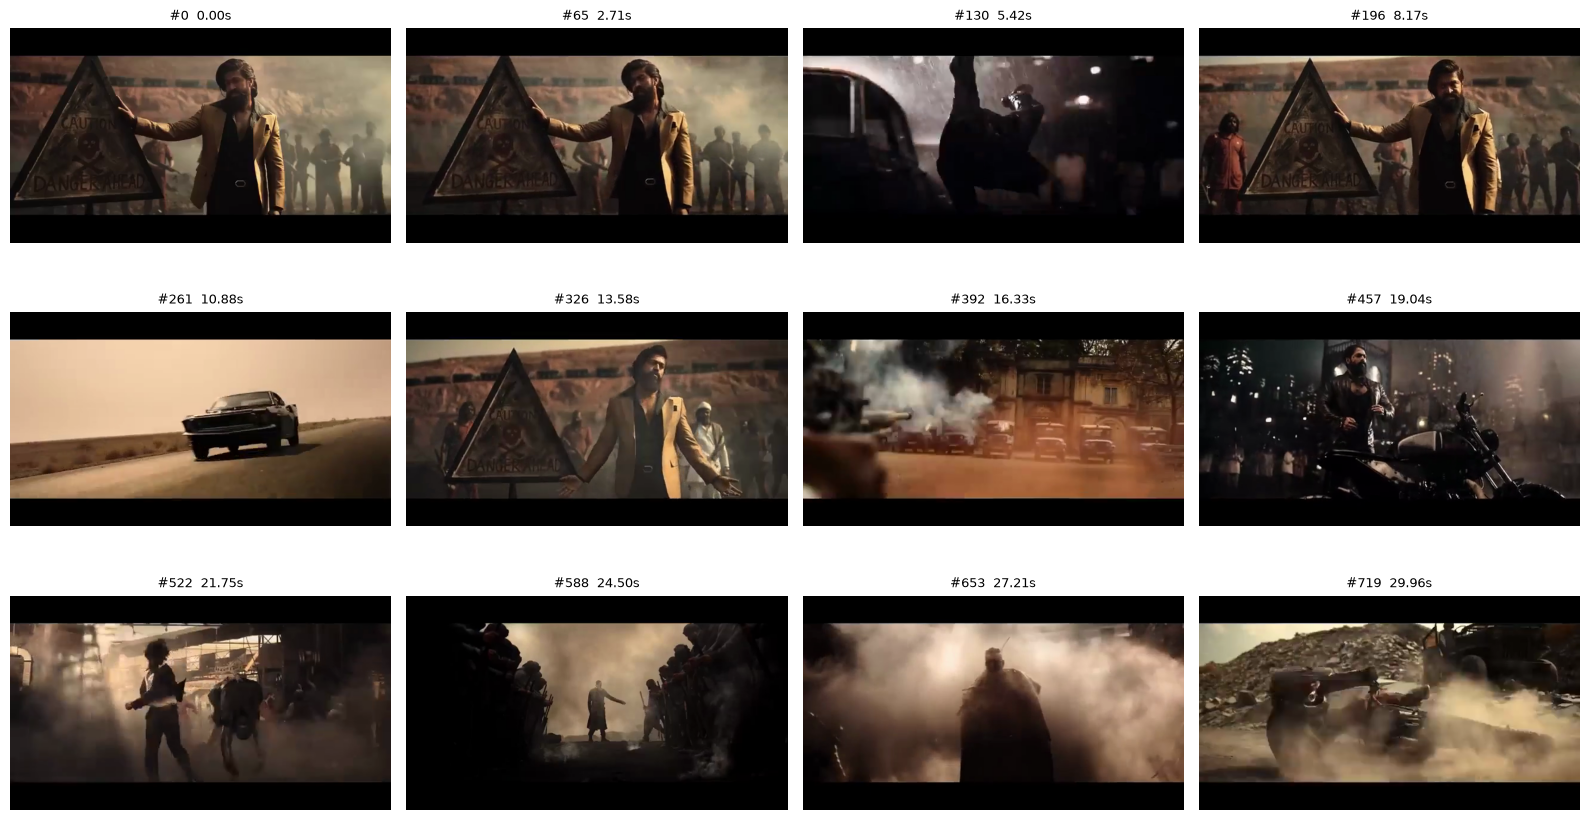

average pixel intensity: 51.528


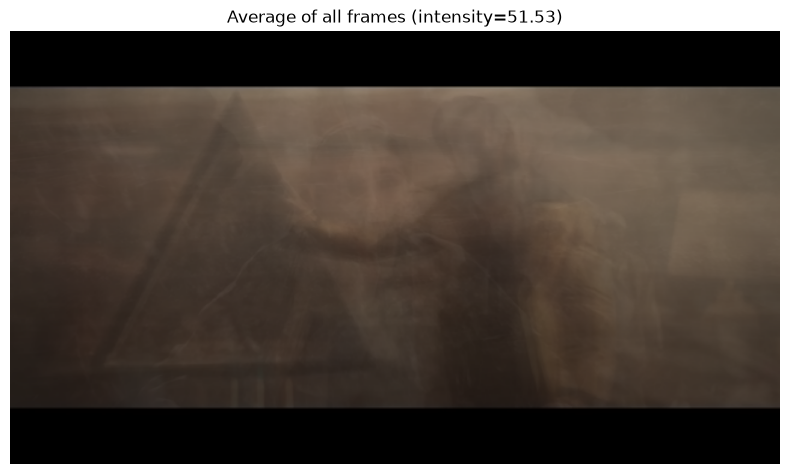

EXTREMA  peaks=18  troughs=17  (prominence≥8.18, distance≥8)
 E#  kind    time_s   frame   intensity
  1  max      3.792      91      70.457
  2  min      3.958      95      21.863
  3  max      5.042     121     124.457
  4  min      5.417     130      28.203
  5  max      5.667     136     133.475
  6  min      6.583     158       0.000
  7  max     10.042     241      72.002
  8  min     10.125     243      47.788
  9  max     10.792     259     102.598
 10  min     11.208     269      16.348
 11  max     11.625     279     101.708
 12  min     11.875     285       0.000
 13  max     13.375     321      51.188
 14  min     13.833     332      41.267
 15  max     13.958     335      89.416
 16  min     14.292     343      73.731
 17  max     15.125     363     106.195
 18  min     15.333     368      95.304
 19  max     15.542     373     103.824
 20  min     15.750     378      17.340
 21  max     16.375     393      73.822
 22  min     16.667     400      48.738
 23  max     16.958

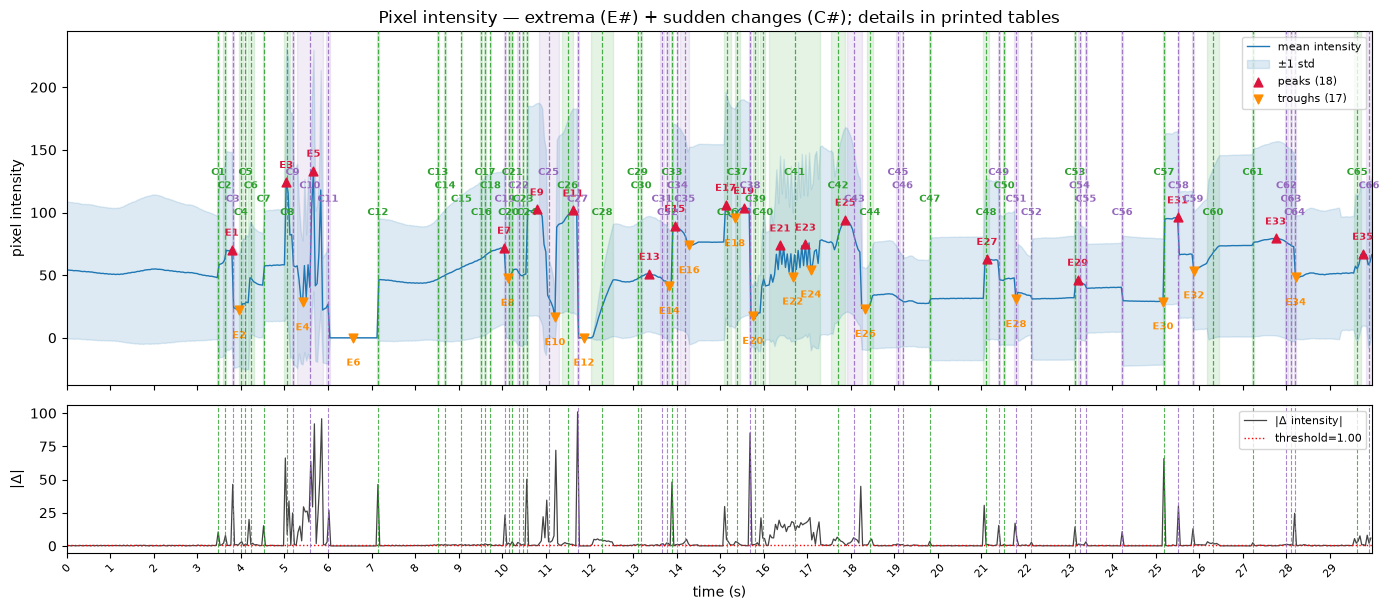

{'n_peaks': 18,
 'n_troughs': 17,
 'n_changes': 66,
 'change_threshold': 1.0,
 'peak_times_s': [3.7916666666666665,
  5.041666666666667,
  5.666666666666667,
  10.041666666666666,
  10.791666666666666,
  11.625,
  13.375,
  13.958333333333334,
  15.125,
  15.541666666666666,
  16.375,
  16.958333333333332,
  17.875,
  21.125,
  23.208333333333332,
  25.5,
  27.75,
  29.75],
 'trough_times_s': [3.9583333333333335,
  5.416666666666667,
  6.583333333333333,
  10.125,
  11.208333333333334,
  11.875,
  13.833333333333334,
  14.291666666666666,
  15.333333333333334,
  15.75,
  16.666666666666668,
  17.083333333333332,
  18.333333333333332,
  21.791666666666668,
  25.166666666666668,
  25.875,
  28.208333333333332],
 'change_mean_times_s': [3.479166666666667,
  3.625,
  3.8125,
  4.0,
  4.104166666666666,
  4.229166666666667,
  4.520833333333334,
  5.0625,
  5.1875,
  5.583333333333334,
  6.0,
  7.145833333333334,
  8.520833333333332,
  8.6875,
  9.0625,
  9.520833333333332,
  9.6041666666666

In [7]:
# --- run: extract + avg + intensity ---
# For long clips: extract_frames(VIDEO_PATH, stride=2, max_frames=300)
frames, timestamps_s = extract_frames(VIDEO_PATH, stride=1,max_frames=720)
print(f"frames shape={frames.shape}  duration≈{timestamps_s[-1]:.2f}s")

show_frame_grid(frames, n=12, timestamps_s=timestamps_s)

avg_img, avg_intensity = average_frame(frames)
print(f"average pixel intensity: {avg_intensity:.3f}")
show_image(avg_img, title=f"Average of all frames (intensity={avg_intensity:.2f})")

intensity = pixel_intensity_stats(frames, timestamps_s=timestamps_s, plot=False)
{k: intensity[k] for k in ("global_mean", "global_min", "global_max", "global_std", "argmax_frame", "argmin_frame")}

extrema = intensity_extrema(
    intensity["per_frame_mean"],
    timestamps_s=timestamps_s,
    per_std=intensity["per_frame_std"],
    # catch small jumps too; raise min_change if too noisy
    min_change=1,
)
{
    "n_peaks": extrema["n_peaks"],
    "n_troughs": extrema["n_troughs"],
    "n_changes": extrema["n_changes"],
    "change_threshold": extrema["change_threshold"],
    "peak_times_s": extrema["peak_times_s"],
    "trough_times_s": extrema["trough_times_s"],
    "change_mean_times_s": extrema["change_mean_times_s"],
}


## 2. Video — pixel diffs

Consecutive absolute difference maps + MAD intensity stats.


In [8]:
def frame_diff_sequence(frames: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Consecutive abs-diff maps (uint8 gray) and per-pair mean MAD in [0, 1].

    Returns
    -------
    diffs : (N-1, H, W) uint8
    mad : (N-1,) float64  — mean abs diff / 255
    """
    grays = np.stack([_to_gray(f) for f in frames], axis=0).astype(np.float32)
    d = np.abs(np.diff(grays, axis=0))
    mad = d.reshape(len(d), -1).mean(axis=1) / 255.0
    diffs = np.clip(d, 0, 255).astype(np.uint8)
    return diffs, mad


def show_diff_at(
    diffs: np.ndarray,
    index: int,
    *,
    mad: np.ndarray | None = None,
    timestamps_s: np.ndarray | None = None,
) -> None:
    title = f"Frame diff #{index}"
    if timestamps_s is not None and index + 1 < len(timestamps_s):
        title += f"  @ {timestamps_s[index + 1]:.3f}s"
    if mad is not None:
        title += f"  MAD={mad[index]:.4f}"
    show_image(diffs[index], title=title, cmap="magma")


def diff_stats(
    mad: np.ndarray,
    *,
    timestamps_s: np.ndarray | None = None,
    plot: bool = True,
) -> dict[str, Any]:
    """avg / max / p95 mean-diff; index of strongest change."""
    stats = {
        "avg_mad": float(mad.mean()),
        "max_mad": float(mad.max()),
        "p95_mad": float(np.percentile(mad, 95)),
        "argmax_diff": int(np.argmax(mad)),
        "max_mad_time_s": (
            float(timestamps_s[int(np.argmax(mad)) + 1])
            if timestamps_s is not None and len(timestamps_s) > int(np.argmax(mad)) + 1
            else None
        ),
    }
    if plot:
        t = (
            timestamps_s[1 : len(mad) + 1]
            if timestamps_s is not None
            else np.arange(1, len(mad) + 1)
        )
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(t, mad, lw=1.0, color="#c0392b")
        ax.axhline(stats["avg_mad"], color="#7f8c8d", ls="--", lw=0.8, label="avg")
        ax.axhline(stats["p95_mad"], color="#e67e22", ls=":", lw=0.8, label="p95")
        ax.set_xlabel("time (s)" if timestamps_s is not None else "frame pair")
        ax.set_ylabel("mean abs diff / 255")
        ax.set_title("Frame-to-frame pixel difference (MAD)")
        ax.legend()
        plt.tight_layout()
        plt.show()
    return stats


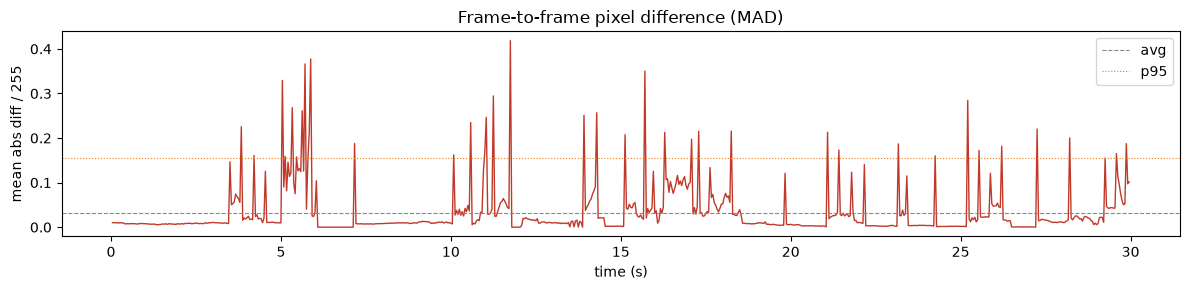

{'avg_mad': 0.032354339957237244, 'max_mad': 0.41849762201309204, 'p95_mad': 0.15537892282009125, 'argmax_diff': 281, 'max_mad_time_s': 11.75}


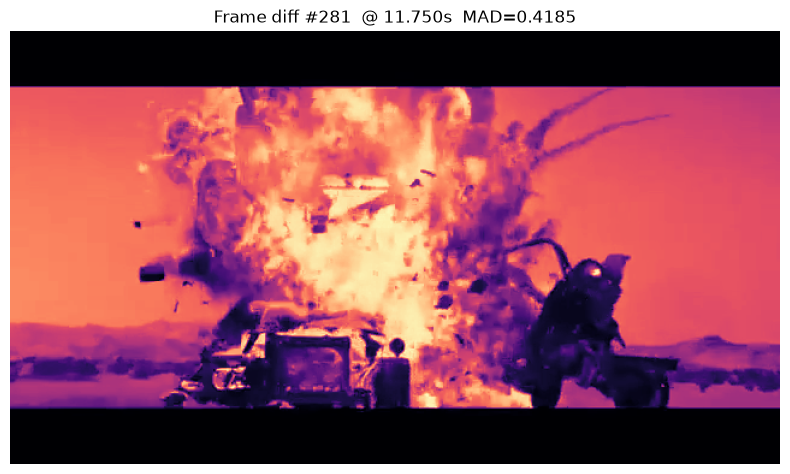

In [9]:
# --- run: diffs ---
diffs, mad = frame_diff_sequence(frames)
dstats = diff_stats(mad, timestamps_s=timestamps_s)
print(dstats)
show_diff_at(diffs, dstats["argmax_diff"], mad=mad, timestamps_s=timestamps_s)


## 3. Video — motion energy + bounding boxes

Global MAD (+ optional Farneback) energy, localized motion bboxes via thresholded diffs, spikes/stops.


In [10]:
def motion_energy_series(
    frames: np.ndarray,
    *,
    use_farneback: bool = True,
    timestamps_s: np.ndarray | None = None,
    plot: bool = True,
) -> dict[str, Any]:
    """Per-frame MAD + optional Farneback mean magnitude → combined energy."""
    grays = [_to_gray(f).astype(np.float32) for f in frames]
    n = len(grays)
    mad_e = np.zeros(n, dtype=np.float64)
    flow_e = np.zeros(n, dtype=np.float64)

    for i in range(1, n):
        mad_e[i] = float(np.mean(np.abs(grays[i] - grays[i - 1]))) / 255.0

    fb_ok = use_farneback
    if use_farneback and n >= 2:
        try:
            prev = grays[0].astype(np.uint8)
            for i in range(1, n):
                cur = grays[i].astype(np.uint8)
                flow = cv2.calcOpticalFlowFarneback(
                    prev, cur, None, 0.5, 3, 15, 3, 5, 1.2, 0
                )
                mag = np.sqrt(flow[..., 0] ** 2 + flow[..., 1] ** 2)
                flow_e[i] = float(np.mean(mag))
                prev = cur
        except Exception as exc:
            print(f"Farneback failed ({exc}); using MAD only.")
            flow_e = mad_e.copy()
            fb_ok = False
    else:
        flow_e = mad_e.copy()
        fb_ok = False

    energy = 0.5 * (mad_e / (mad_e.max() + 1e-9) + flow_e / (flow_e.max() + 1e-9))
    t = timestamps_s if timestamps_s is not None else np.arange(n)

    if plot:
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(t, mad_e, lw=0.9, label="MAD", alpha=0.8)
        if fb_ok:
            ax.plot(t, flow_e / (flow_e.max() + 1e-9), lw=0.9, label="flow (norm)", alpha=0.8)
        ax.plot(t, energy, lw=1.2, label="combined energy", color="#2c3e50")
        ax.set_xlabel("time (s)" if timestamps_s is not None else "frame")
        ax.set_ylabel("energy")
        ax.set_title("Motion energy")
        ax.legend()
        plt.tight_layout()
        plt.show()

    return {
        "mad": mad_e,
        "flow_energy": flow_e,
        "energy": energy,
        "avg_energy": float(energy.mean()),
        "max_energy": float(energy.max()),
        "argmax_energy": int(np.argmax(energy)),
    }


def motion_bounding_boxes(
    frames: np.ndarray,
    *,
    timestamps_s: np.ndarray | None = None,
    thr: float | None = None,
    min_area: int = 64,
) -> list[dict[str, Any]]:
    """Largest motion bbox per consecutive frame pair via thresholded abs-diff."""
    grays = [_to_gray(f) for f in frames]
    results: list[dict[str, Any]] = []

    pair_mads: list[float] = []
    for i in range(1, len(grays)):
        pair_mads.append(
            float(np.mean(np.abs(grays[i].astype(np.float32) - grays[i - 1].astype(np.float32))))
        )
    pair_mads_arr = np.asarray(pair_mads, dtype=np.float64)
    if thr is None:
        thr = float(np.mean(pair_mads_arr) + 1.5 * (np.std(pair_mads_arr) + 1e-9))
        thr = max(thr, 8.0)  # pixel units on uint8 gray

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

    for i in range(1, len(grays)):
        diff = cv2.absdiff(grays[i], grays[i - 1])
        energy = float(np.mean(diff)) / 255.0
        _, mask = cv2.threshold(diff, thr, 255, cv2.THRESH_BINARY)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        best = None
        best_area = 0
        for c in contours:
            x, y, w, h = cv2.boundingRect(c)
            area = int(w * h)
            if area >= min_area and area > best_area:
                best_area = area
                best = (x, y, w, h)

        t = float(timestamps_s[i]) if timestamps_s is not None else float(i)
        results.append({
            "frame_index": i,
            "t_s": t,
            "t_ms": int(round(t * 1000)),
            "energy": energy,
            "bbox": best,
            "area": best_area if best else 0,
            "score": energy * (best_area if best else 0),
        })

    return results


def highest_motion_bbox(
    bboxes: list[dict[str, Any]],
    frames: np.ndarray,
    diffs: np.ndarray | None = None,
    *,
    show: bool = True,
) -> dict[str, Any] | None:
    """Pick frame with max energy×area; optionally draw bbox on frame + diff."""
    scored = [b for b in bboxes if b.get("bbox")]
    if not scored:
        print("No motion bboxes found.")
        return None

    best = max(scored, key=lambda b: b["score"])
    i = int(best["frame_index"])
    x, y, w, h = best["bbox"]

    if show:
        frame_vis = frames[i].copy()
        if frame_vis.ndim == 2:
            frame_vis = cv2.cvtColor(frame_vis, cv2.COLOR_GRAY2RGB)
        cv2.rectangle(frame_vis, (x, y), (x + w, y + h), (255, 40, 40), 2)
        show_image(
            frame_vis,
            title=(
                f"Highest motion bbox  t={best['t_s']:.3f}s  "
                f"bbox={best['bbox']}  area={best['area']}  energy={best['energy']:.4f}"
            ),
        )
        if diffs is not None and i - 1 < len(diffs):
            dvis = diffs[i - 1].copy()
            dvis_rgb = cv2.cvtColor(dvis, cv2.COLOR_GRAY2RGB)
            cv2.rectangle(dvis_rgb, (x, y), (x + w, y + h), (255, 40, 40), 2)
            show_image(dvis_rgb, title="Diff map with same bbox")

    return best


def detect_motion_events(
    energy: np.ndarray,
    timestamps_s: np.ndarray,
    *,
    spike_k: float = 2.0,
    stop_k: float = 2.0,
) -> list[dict[str, Any]]:
    """Motion spike / stop events using mean±k·std on Δenergy (pipeline-style)."""
    d_energy = np.diff(energy, prepend=energy[0])
    spike_thr = float(np.mean(d_energy) + spike_k * (np.std(d_energy) + 1e-9))
    stop_thr = float(np.mean(d_energy) - stop_k * (np.std(d_energy) + 1e-9))
    events: list[dict[str, Any]] = []

    for i in range(1, len(energy) - 1):
        t_ms = int(round(float(timestamps_s[i]) * 1000))
        if d_energy[i] >= spike_thr and d_energy[i] >= d_energy[i - 1] and d_energy[i] >= d_energy[i + 1]:
            events.append({
                "kind": "motion_spike",
                "frame_index": i,
                "t_ms": t_ms,
                "t_s": float(timestamps_s[i]),
                "strength": float(d_energy[i]),
            })
        if d_energy[i] <= stop_thr and d_energy[i] <= d_energy[i - 1] and d_energy[i] <= d_energy[i + 1]:
            if energy[i - 1] > float(np.median(energy) + np.std(energy)):
                events.append({
                    "kind": "motion_stop",
                    "frame_index": i,
                    "t_ms": t_ms,
                    "t_s": float(timestamps_s[i]),
                    "strength": float(-d_energy[i]),
                })
    return events


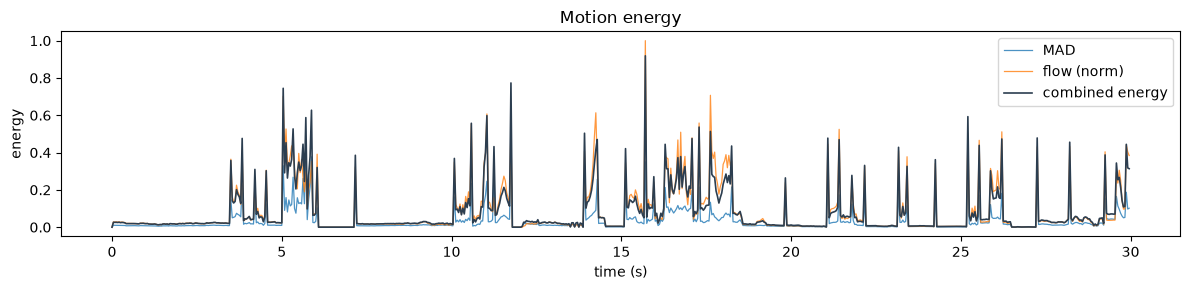

{'avg_energy': 0.07957752658691226, 'max_energy': 0.9186041380608532, 'argmax_energy': 377}


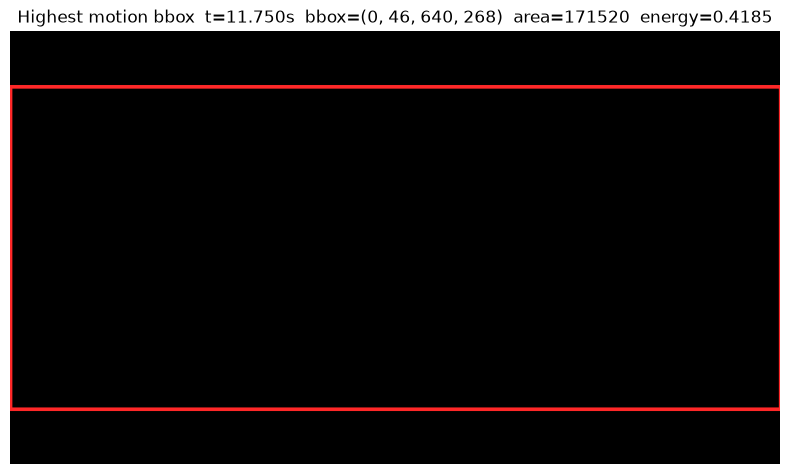

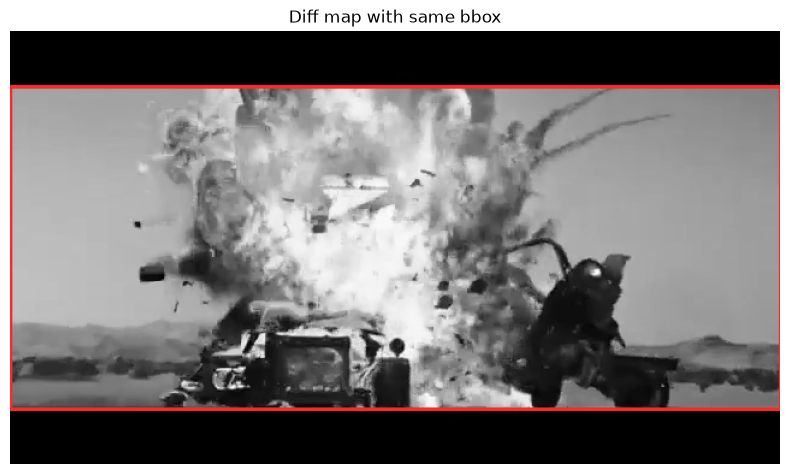

highest motion bbox: {'frame_index': 282, 't_s': 11.75, 't_ms': 11750, 'energy': 0.4184976171023965, 'bbox': (0, 46, 640, 268), 'area': 171520, 'score': 71780.71128540306}
motion events: 58


[{'kind': 'motion_spike',
  'frame_index': 84,
  't_ms': 3500,
  't_s': 3.5,
  'strength': 0.3373692304785324},
 {'kind': 'motion_spike',
  'frame_index': 92,
  't_ms': 3833,
  't_s': 3.8333333333333335,
  'strength': 0.348204075489679},
 {'kind': 'motion_stop',
  'frame_index': 93,
  't_ms': 3875,
  't_s': 3.875,
  'strength': 0.44002446537531004},
 {'kind': 'motion_stop',
  'frame_index': 110,
  't_ms': 4583,
  't_s': 4.583333333333333,
  'strength': 0.27601773606860824},
 {'kind': 'motion_spike',
  'frame_index': 121,
  't_ms': 5042,
  't_s': 5.041666666666667,
  'strength': 0.7212901207222348},
 {'kind': 'motion_stop',
  'frame_index': 122,
  't_ms': 5083,
  't_s': 5.083333333333333,
  'strength': 0.4532298887233992},
 {'kind': 'motion_spike',
  'frame_index': 137,
  't_ms': 5708,
  't_s': 5.708333333333333,
  'strength': 0.3423820162573318},
 {'kind': 'motion_stop',
  'frame_index': 138,
  't_ms': 5750,
  't_s': 5.75,
  'strength': 0.4895277401942808},
 {'kind': 'motion_stop',
  '

In [11]:
# --- run: motion ---
# Farneback is slower; set use_farneback=False for a quick pass.
motion = motion_energy_series(frames, use_farneback=True, timestamps_s=timestamps_s)
print({
    "avg_energy": motion["avg_energy"],
    "max_energy": motion["max_energy"],
    "argmax_energy": motion["argmax_energy"],
})

bboxes = motion_bounding_boxes(frames, timestamps_s=timestamps_s)
best_bbox = highest_motion_bbox(bboxes, frames, diffs)
print("highest motion bbox:", best_bbox)

motion_events = detect_motion_events(motion["energy"], timestamps_s)
print(f"motion events: {len(motion_events)}")
motion_events[:10]


## 4. Video — scene anchors

Cut detection from MAD peaks + summary table. Optional overlay from pipeline `anchors.json`.


In [12]:
def detect_scene_cuts(
    frames: np.ndarray,
    timestamps_s: np.ndarray,
    *,
    k: float = 2.5,
) -> list[dict[str, Any]]:
    """Detect scene cuts as local MAD peaks above mean + k·std."""
    grays = np.stack([_to_gray(f) for f in frames], axis=0).astype(np.float32)
    diffs_arr = np.zeros(len(grays), dtype=np.float64)
    for i in range(1, len(grays)):
        diffs_arr[i] = float(np.mean(np.abs(grays[i] - grays[i - 1]))) / 255.0

    cut_thr = float(np.mean(diffs_arr) + k * (np.std(diffs_arr) + 1e-9))
    cuts: list[dict[str, Any]] = []
    for i in range(1, len(diffs_arr) - 1):
        if diffs_arr[i] >= cut_thr and diffs_arr[i] >= diffs_arr[i - 1] and diffs_arr[i] >= diffs_arr[i + 1]:
            cuts.append({
                "kind": "cut",
                "frame_index": i,
                "t_s": float(timestamps_s[i]),
                "t_ms": int(round(float(timestamps_s[i]) * 1000)),
                "strength": float(diffs_arr[i]),
            })
    return cuts


def summarize_scene_anchors(
    cuts: list[dict[str, Any]],
    motion_events: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    """Merge cut / motion_spike / motion_stop into a time-sorted list."""
    anchors = list(cuts) + list(motion_events)
    anchors.sort(key=lambda a: (a.get("t_ms", 0), a.get("kind", "")))
    return anchors


def load_pipeline_anchors(
    features_dir: str | Path,
    video_id: str,
    clip_id: str,
) -> dict[str, Any] | None:
    """Optionally load production Layer-0 anchors.json if present."""
    path = Path(features_dir) / video_id / clip_id / "perception" / "anchors.json"
    if not path.is_file():
        print(f"No anchors.json at {path}")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def plot_scene_anchors(
    anchors: list[dict[str, Any]],
    *,
    energy: np.ndarray | None = None,
    timestamps_s: np.ndarray | None = None,
) -> None:
    fig, ax = plt.subplots(figsize=(12, 3))
    if energy is not None and timestamps_s is not None:
        ax.plot(timestamps_s, energy, color="#7f8c8d", lw=0.9, label="motion energy")
    colors = {"cut": "#e74c3c", "motion_spike": "#8e44ad", "motion_stop": "#2980b9"}
    for a in anchors:
        ax.axvline(
            a["t_s"],
            color=colors.get(a["kind"], "#333"),
            alpha=0.55,
            lw=1.0,
            label=a["kind"],
        )
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc="upper right")
    ax.set_xlabel("time (s)")
    ax.set_title("Scene / motion anchors")
    plt.tight_layout()
    plt.show()


cuts=28  total anchors=86


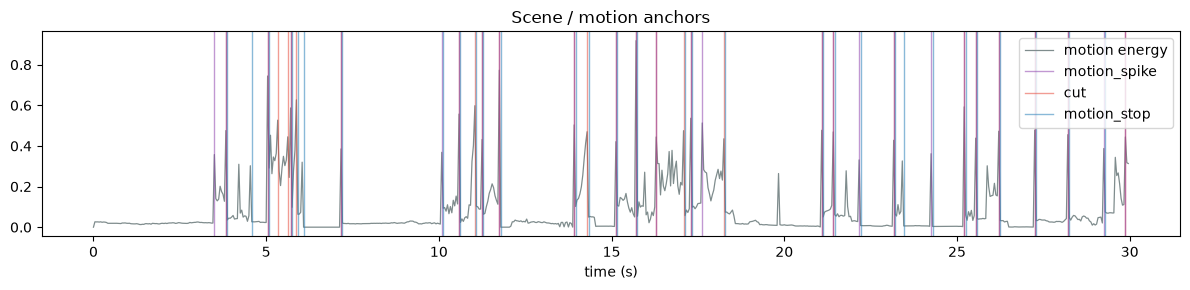

[{'kind': 'motion_spike',
  'frame_index': 84,
  't_ms': 3500,
  't_s': 3.5,
  'strength': 0.3373692304785324},
 {'kind': 'cut',
  'frame_index': 92,
  't_s': 3.8333333333333335,
  't_ms': 3833,
  'strength': 0.22549882776596966},
 {'kind': 'motion_spike',
  'frame_index': 92,
  't_ms': 3833,
  't_s': 3.8333333333333335,
  'strength': 0.348204075489679},
 {'kind': 'motion_stop',
  'frame_index': 93,
  't_ms': 3875,
  't_s': 3.875,
  'strength': 0.44002446537531004},
 {'kind': 'motion_stop',
  'frame_index': 110,
  't_ms': 4583,
  't_s': 4.583333333333333,
  'strength': 0.27601773606860824},
 {'kind': 'cut',
  'frame_index': 121,
  't_s': 5.041666666666667,
  't_ms': 5042,
  'strength': 0.3293927360983456},
 {'kind': 'motion_spike',
  'frame_index': 121,
  't_ms': 5042,
  't_s': 5.041666666666667,
  'strength': 0.7212901207222348},
 {'kind': 'motion_stop',
  'frame_index': 122,
  't_ms': 5083,
  't_s': 5.083333333333333,
  'strength': 0.4532298887233992},
 {'kind': 'cut',
  'frame_index

In [13]:
# --- run: scene anchors ---
cuts = detect_scene_cuts(frames, timestamps_s)
scene_anchors = summarize_scene_anchors(cuts, motion_events)
print(f"cuts={len(cuts)}  total anchors={len(scene_anchors)}")
plot_scene_anchors(scene_anchors, energy=motion["energy"], timestamps_s=timestamps_s)
scene_anchors[:20]

# Optional: overlay pipeline anchors if this clip was already processed
# pipe_anchors = load_pipeline_anchors(REPO_ROOT / "Dataset" / "extracted" / "features", "JKa05nyUmuQ", "clip_005")
# pipe_anchors["anchors"][:5] if pipe_anchors else None


## 5. Audio — load + waveform

In [14]:
def load_audio(
    path: str | Path,
    sr: int = 22050,
    *,
    prefer_pipeline_decode: bool = True,
) -> tuple[np.ndarray, int]:
    """Load mono float waveform from a video/audio file.

    Prefers ``perception.audio_io.decode_mono`` (ffmpeg) because librosa/soundfile
    often cannot open MP4 containers directly. Falls back to ``librosa.load``.
    """
    path = Path(path)
    if prefer_pipeline_decode:
        try:
            from perception.audio_io import decode_mono

            y = decode_mono(path, sample_rate=sr)
            return np.asarray(y, dtype=np.float32), sr
        except Exception as exc:
            print(f"decode_mono failed ({exc}); falling back to librosa.load")

    try:
        y, out_sr = librosa.load(str(path), sr=sr, mono=True)
        return y.astype(np.float32), int(out_sr)
    except Exception:
        # Last resort: ffmpeg → temp-less raw via decode_mono even if prefer was False
        from perception.audio_io import decode_mono

        y = decode_mono(path, sample_rate=sr)
        return np.asarray(y, dtype=np.float32), sr


def plot_waveform(y: np.ndarray, sr: int, *, figsize: tuple[float, float] = (12, 3)) -> None:
    t = np.arange(len(y)) / float(sr)
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(t, y, color="#34495e", lw=0.4)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude")
    ax.set_title("Waveform")
    plt.tight_layout()
    plt.show()


def waveform_stats(
    y: np.ndarray,
    sr: int,
    *,
    plot: bool = True,
) -> dict[str, Any]:
    """duration, rms, peak, crest factor, zero-crossing rate."""
    y64 = np.asarray(y, dtype=np.float64)
    peak = float(np.max(np.abs(y64))) if y64.size else 0.0
    rms = float(np.sqrt(np.mean(y64 ** 2))) if y64.size else 0.0
    zcr = float(librosa.feature.zero_crossing_rate(y.astype(np.float32)).mean()) if y64.size else 0.0
    stats = {
        "duration_s": float(len(y64) / sr) if sr else 0.0,
        "n_samples": int(len(y64)),
        "sample_rate": int(sr),
        "rms": rms,
        "peak": peak,
        "crest_factor": float(peak / (rms + 1e-12)),
        "zero_crossing_rate": zcr,
        "mean": float(y64.mean()) if y64.size else 0.0,
        "std": float(y64.std()) if y64.size else 0.0,
    }
    if plot:
        plot_waveform(y, sr)
    return stats


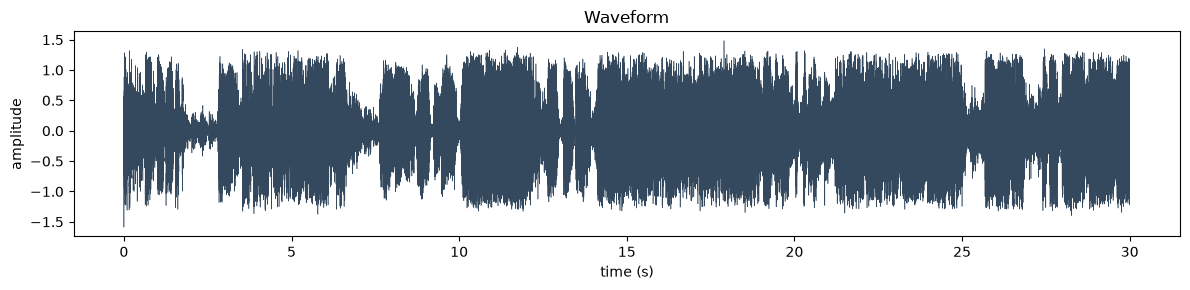

{'duration_s': 30.00018140589569,
 'n_samples': 661504,
 'sample_rate': 22050,
 'rms': 0.4521223383114585,
 'peak': 1.58784818649292,
 'crest_factor': 3.5119879111028784,
 'zero_crossing_rate': 0.0835655784754447,
 'mean': -4.7347199556424444e-05,
 'std': 0.4521223358323095}

In [15]:
# --- run: audio waveform ---
y, sr = load_audio(VIDEO_PATH, sr=22050)
wstats = waveform_stats(y, sr)
wstats


## 6. Audio — spectrogram + spectrogram diff

In [16]:
def compute_spectrogram(
    y: np.ndarray,
    sr: int,
    *,
    n_fft: int = 2048,
    hop_length: int = 512,
    mel: bool = False,
    n_mels: int = 128,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Power spectrogram (linear STFT or mel). Returns S, times, freqs."""
    if mel:
        S = librosa.feature.melspectrogram(
            y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels, power=2.0
        )
        freqs = librosa.mel_frequencies(n_mels=n_mels, fmin=0.0, fmax=sr / 2.0)
    else:
        stft = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
        S = np.abs(stft) ** 2
        freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    times = librosa.frames_to_time(np.arange(S.shape[1]), sr=sr, hop_length=hop_length)
    return S, times, freqs


def plot_spectrogram(
    S: np.ndarray,
    times: np.ndarray,
    freqs: np.ndarray,
    *,
    title: str = "Spectrogram (dB)",
    figsize: tuple[float, float] = (12, 4),
    mel: bool = False,
) -> None:
    S_db = librosa.power_to_db(S, ref=np.max)
    fig, ax = plt.subplots(figsize=figsize)
    img = ax.imshow(
        S_db,
        origin="lower",
        aspect="auto",
        extent=[times[0], times[-1] if len(times) else 0, freqs[0], freqs[-1] if len(freqs) else 1],
        cmap="magma",
    )
    ax.set_xlabel("time (s)")
    ax.set_ylabel("mel bin" if mel else "Hz")
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
    plt.tight_layout()
    plt.show()


def spectrogram_diff(S: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Frame-to-frame abs diff along time → dS image + mean spectral flux curve."""
    S_db = librosa.power_to_db(S + 1e-12, ref=np.max)
    dS = np.abs(np.diff(S_db, axis=1))
    flux = dS.mean(axis=0)
    return dS, flux


def plot_spectrogram_diff(
    dS: np.ndarray,
    times: np.ndarray,
    freqs: np.ndarray,
    flux: np.ndarray | None = None,
    *,
    figsize: tuple[float, float] = (12, 5),
) -> None:
    if len(times) >= 2:
        t_diff = 0.5 * (times[:-1] + times[1:])
        t0, t1 = float(t_diff[0]), float(t_diff[-1])
    else:
        t_diff = times
        t0, t1 = 0.0, 1.0

    if flux is not None:
        fig, axes = plt.subplots(
            2, 1, figsize=figsize, sharex=True, gridspec_kw={"height_ratios": [3, 1]}
        )
        ax0, ax1 = axes
    else:
        fig, ax0 = plt.subplots(figsize=figsize)
        ax1 = None

    img = ax0.imshow(
        dS,
        origin="lower",
        aspect="auto",
        extent=[t0, t1, freqs[0], freqs[-1] if len(freqs) else 1],
        cmap="inferno",
    )
    ax0.set_ylabel("Hz")
    ax0.set_title("Spectrogram diff (|ΔdB|)")
    fig.colorbar(img, ax=ax0, fraction=0.046, pad=0.04)

    if ax1 is not None and flux is not None:
        ax1.plot(t_diff[: len(flux)], flux, color="#e74c3c", lw=1.0)
        ax1.set_xlabel("time (s)")
        ax1.set_ylabel("mean flux")
        ax1.set_title("Spectral flux")

    plt.tight_layout()
    plt.show()


def audio_spectral_stats(
    S: np.ndarray,
    dS: np.ndarray,
    times: np.ndarray,
    flux: np.ndarray,
) -> dict[str, Any]:
    """mean/max dB, spectral flux avg/max, loudest / strongest-flux time bins."""
    S_db = librosa.power_to_db(S + 1e-12, ref=np.max)
    frame_energy = S_db.mean(axis=0)
    loudest_i = int(np.argmax(frame_energy))
    flux_i = int(np.argmax(flux)) if flux.size else 0
    t_diff = 0.5 * (times[:-1] + times[1:]) if len(times) >= 2 else times

    return {
        "mean_db": float(S_db.mean()),
        "max_db": float(S_db.max()),
        "min_db": float(S_db.min()),
        "avg_spectral_flux": float(flux.mean()) if flux.size else 0.0,
        "max_spectral_flux": float(flux.max()) if flux.size else 0.0,
        "loudest_time_s": float(times[loudest_i]) if len(times) else None,
        "loudest_frame": loudest_i,
        "strongest_flux_time_s": float(t_diff[flux_i]) if len(t_diff) else None,
        "strongest_flux_frame": flux_i,
        "diff_mean": float(dS.mean()) if dS.size else 0.0,
        "diff_max": float(dS.max()) if dS.size else 0.0,
    }


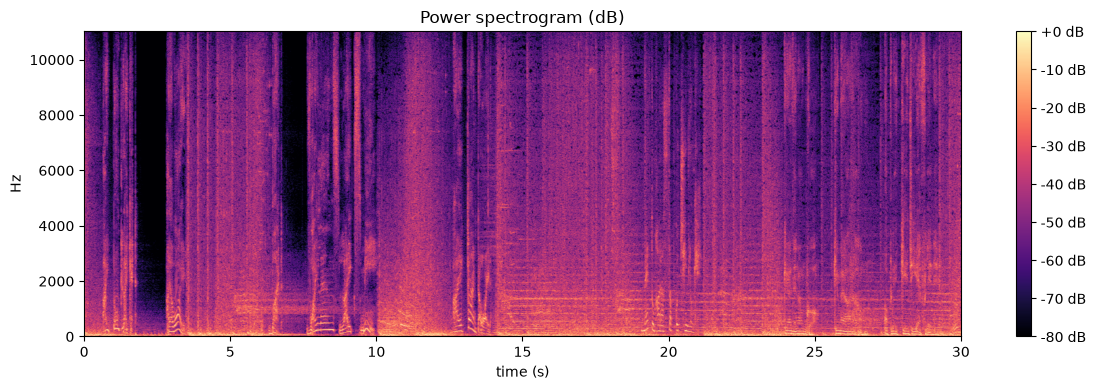

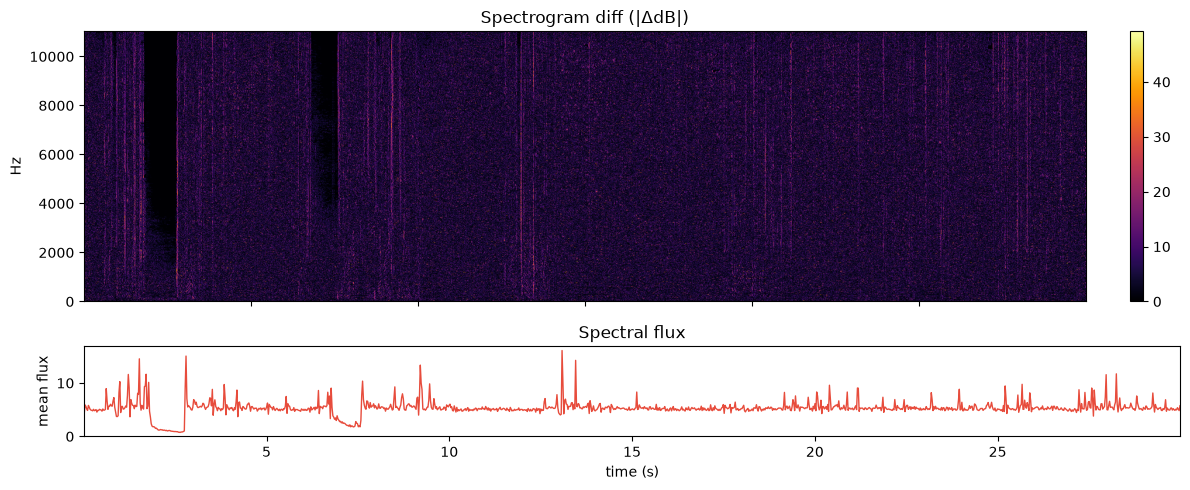

{'mean_db': -50.66864013671875,
 'max_db': 0.0,
 'min_db': -80.0,
 'avg_spectral_flux': 5.284459590911865,
 'max_spectral_flux': 16.08418083190918,
 'loudest_time_s': 3.5526530612244898,
 'loudest_frame': 153,
 'strongest_flux_time_s': 13.084444444444443,
 'strongest_flux_frame': 563,
 'diff_mean': 5.284459590911865,
 'diff_max': 49.21811294555664}

In [17]:
# --- run: spectrogram ---
S, spec_times, freqs = compute_spectrogram(y, sr, n_fft=2048, hop_length=512, mel=False)
plot_spectrogram(S, spec_times, freqs, title="Power spectrogram (dB)")

dS, flux = spectrogram_diff(S)
plot_spectrogram_diff(dS, spec_times, freqs, flux)

sstats = audio_spectral_stats(S, dS, spec_times, flux)
sstats


## 7. Combined summary — `analyze_video_and_audio`

One-shot wrapper. Individual functions above remain independently callable.


In [18]:
def analyze_video_and_audio(
    path: str | Path,
    *,
    stride: int = 1,
    max_frames: int | None = None,
    analysis_width: int | None = None,
    use_farneback: bool = True,
    audio_sr: int = 22050,
    mel: bool = False,
) -> dict[str, Any]:
    """Run video + audio analysis and show key figures; return a compact stats dict."""
    path = Path(path)
    print("=" * 60)
    print(f"Analyzing: {path}")
    print("=" * 60)

    meta = probe_video(path)
    print("probe:", {k: meta[k] for k in meta if k != "path"})

    frames, timestamps_s = extract_frames(
        path, stride=stride, max_frames=max_frames, analysis_width=analysis_width
    )
    show_frame_grid(frames, n=8, timestamps_s=timestamps_s)

    avg_img, avg_intensity = average_frame(frames)
    show_image(avg_img, title=f"Average frame (intensity={avg_intensity:.2f})")
    intensity = pixel_intensity_stats(frames, timestamps_s=timestamps_s, plot=True)

    diffs, mad = frame_diff_sequence(frames)
    dstats = diff_stats(mad, timestamps_s=timestamps_s, plot=True)
    show_diff_at(diffs, dstats["argmax_diff"], mad=mad, timestamps_s=timestamps_s)

    motion = motion_energy_series(
        frames, use_farneback=use_farneback, timestamps_s=timestamps_s, plot=True
    )
    bboxes = motion_bounding_boxes(frames, timestamps_s=timestamps_s)
    best_bbox = highest_motion_bbox(bboxes, frames, diffs, show=True)
    motion_events = detect_motion_events(motion["energy"], timestamps_s)

    cuts = detect_scene_cuts(frames, timestamps_s)
    anchors = summarize_scene_anchors(cuts, motion_events)
    plot_scene_anchors(anchors, energy=motion["energy"], timestamps_s=timestamps_s)

    y, sr = load_audio(path, sr=audio_sr)
    wstats = waveform_stats(y, sr, plot=True)

    S, spec_times, freqs = compute_spectrogram(y, sr, mel=mel)
    plot_spectrogram(S, spec_times, freqs, title="Spectrogram (dB)", mel=mel)
    dS, flux = spectrogram_diff(S)
    plot_spectrogram_diff(dS, spec_times, freqs, flux)
    sstats = audio_spectral_stats(S, dS, spec_times, flux)

    summary = {
        "path": str(path),
        "video": {
            "probe": meta,
            "n_frames_loaded": int(len(frames)),
            "avg_pixel_intensity": avg_intensity,
            "intensity": {
                k: intensity[k]
                for k in (
                    "global_mean",
                    "global_min",
                    "global_max",
                    "global_std",
                    "argmax_frame",
                    "argmin_frame",
                )
            },
            "diff": dstats,
            "motion": {
                "avg_energy": motion["avg_energy"],
                "max_energy": motion["max_energy"],
                "argmax_energy": motion["argmax_energy"],
                "n_events": len(motion_events),
            },
            "highest_motion_bbox": best_bbox,
            "n_cuts": len(cuts),
            "n_scene_anchors": len(anchors),
            "scene_anchors": anchors,
        },
        "audio": {
            "waveform": wstats,
            "spectral": sstats,
        },
    }

    print("\n--- SUMMARY ---")
    print(
        json.dumps(
            {
                "avg_pixel_intensity": avg_intensity,
                "diff": dstats,
                "motion": summary["video"]["motion"],
                "highest_motion_bbox": best_bbox,
                "n_cuts": len(cuts),
                "n_scene_anchors": len(anchors),
                "waveform": wstats,
                "spectral": sstats,
            },
            indent=2,
            default=str,
        )
    )
    return summary


Analyzing: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/JKa05nyUmuQ/clip_003.mp4
probe: {'available': True, 'fps': 24.0, 'n_frames': 720, 'width': 640, 'height': 360, 'duration_s': 30.0, 'has_audio': True}


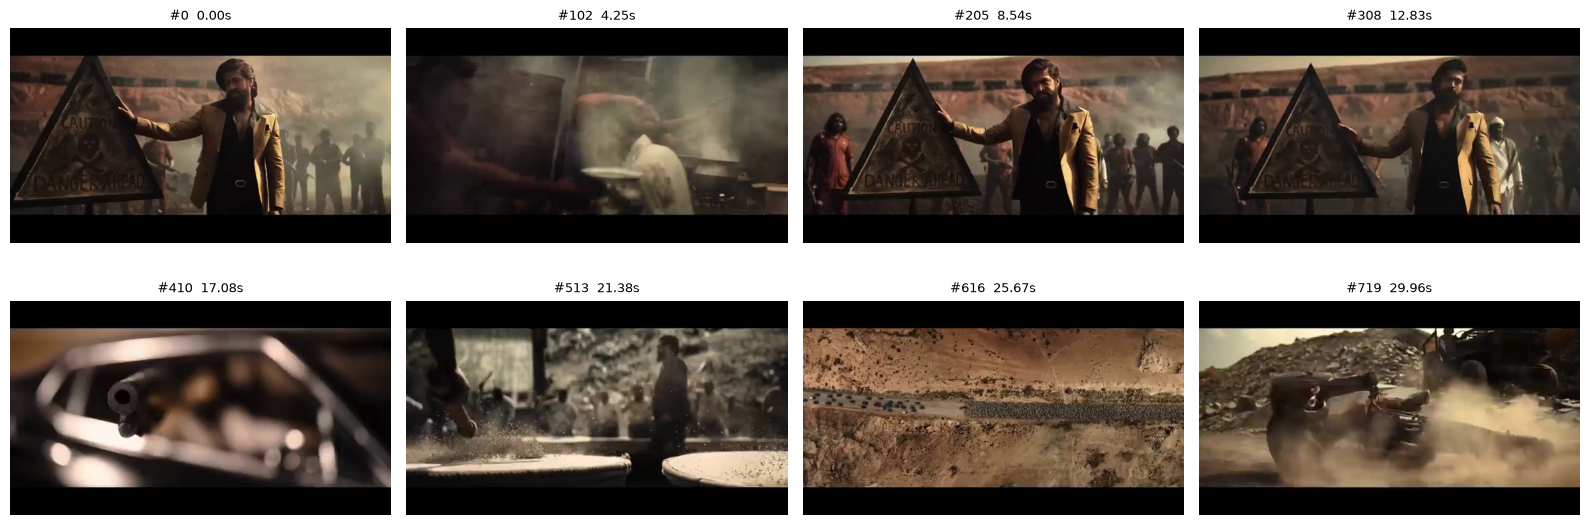

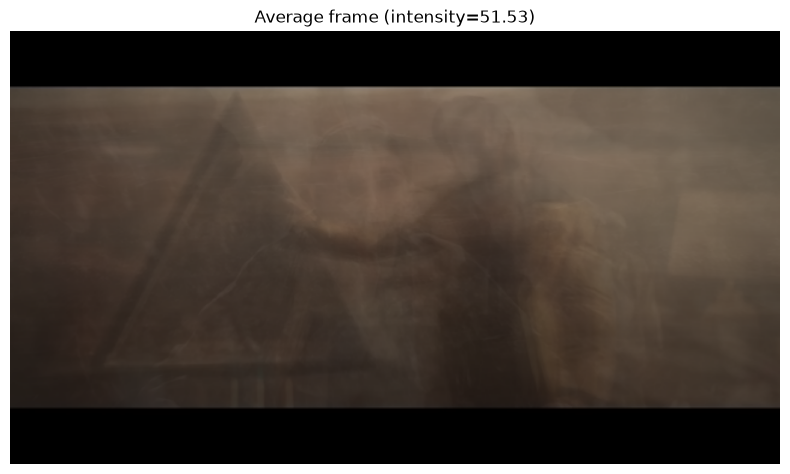

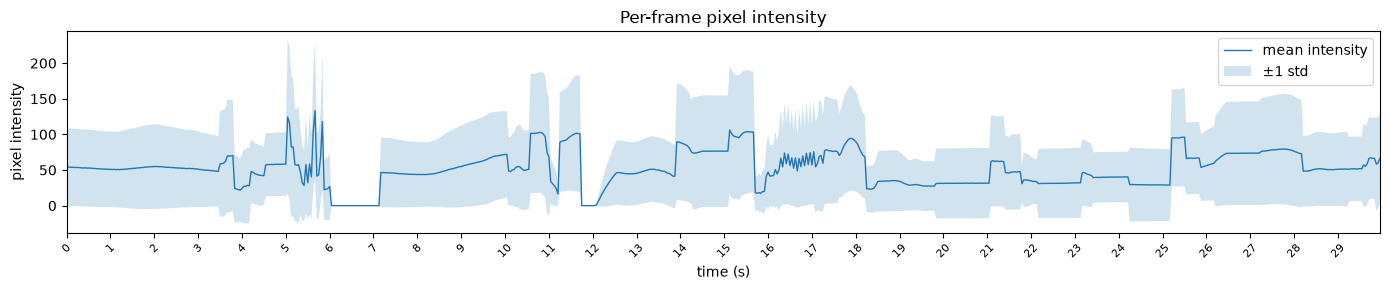

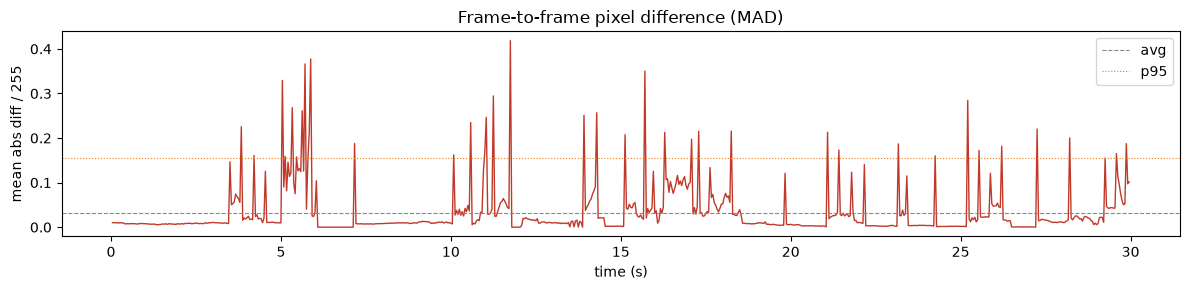

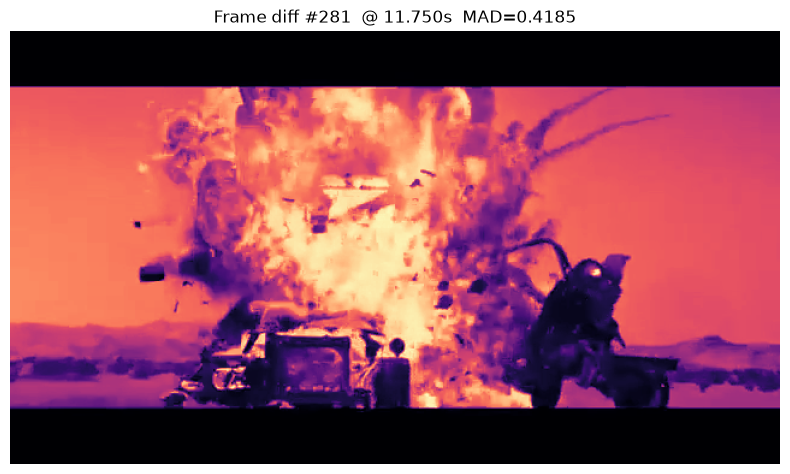

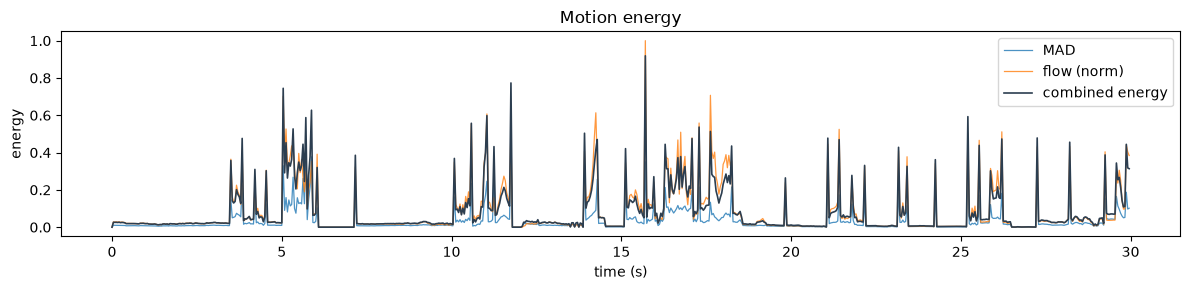

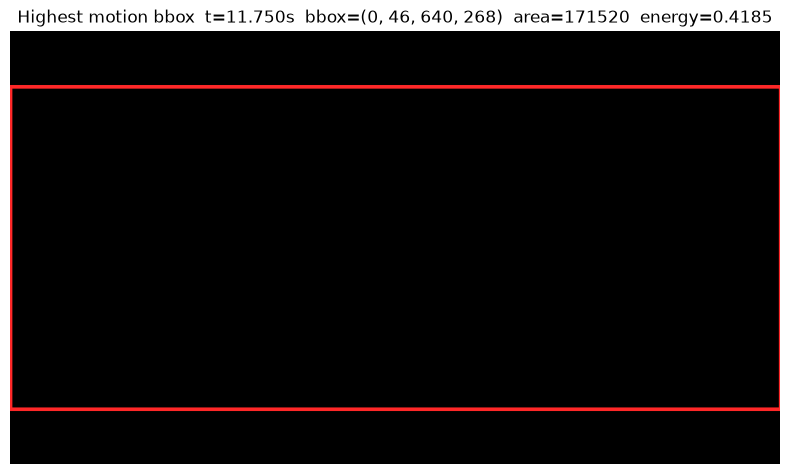

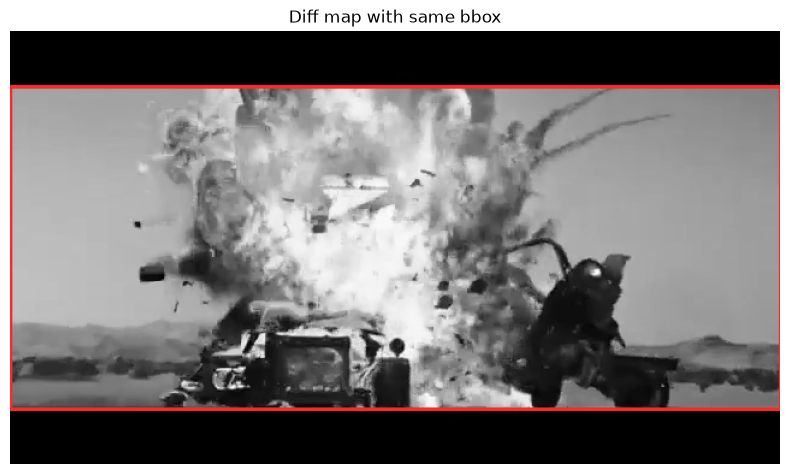

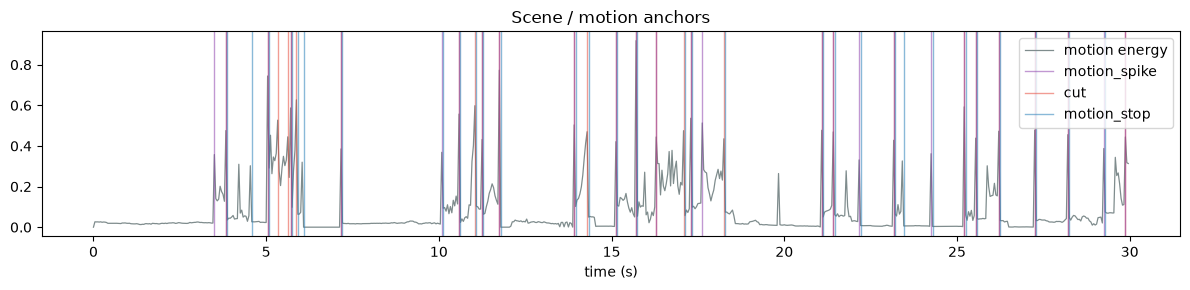

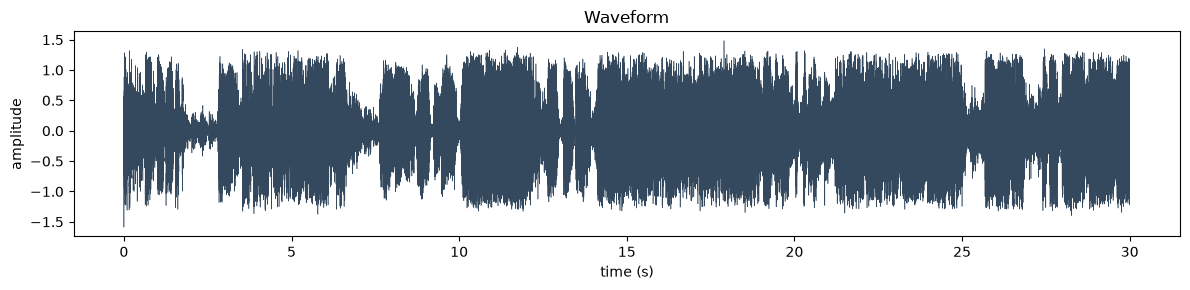

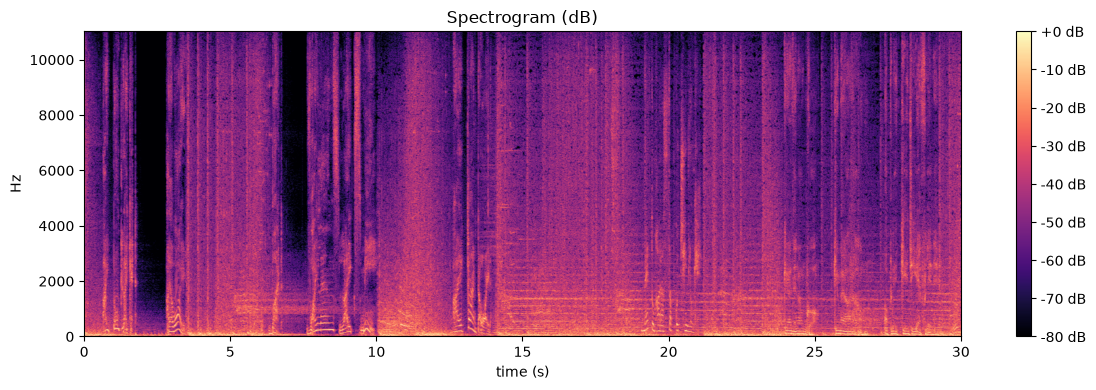

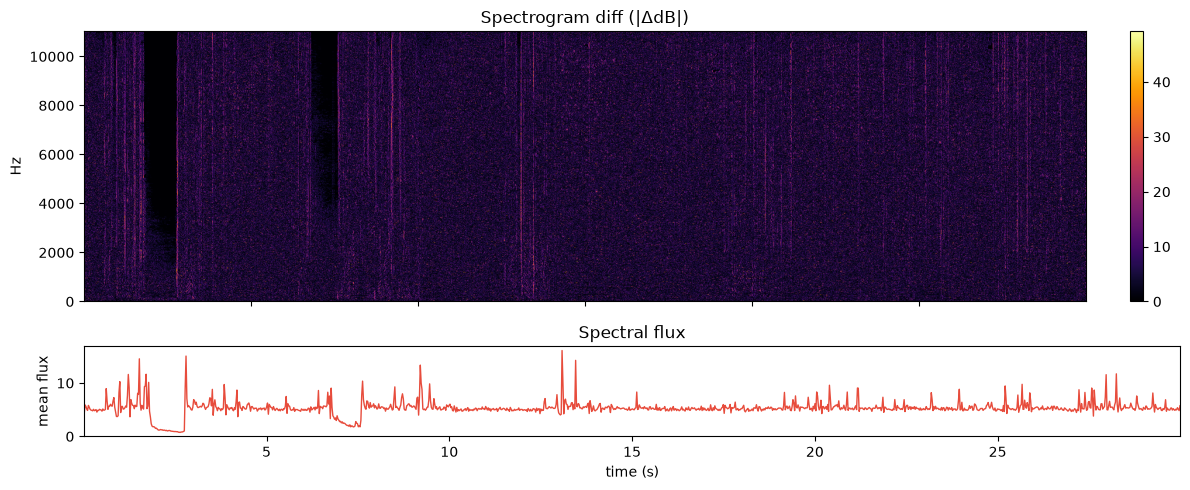


--- SUMMARY ---
{
  "avg_pixel_intensity": 51.52760038499871,
  "diff": {
    "avg_mad": 0.032354339957237244,
    "max_mad": 0.41849762201309204,
    "p95_mad": 0.15537892282009125,
    "argmax_diff": 281,
    "max_mad_time_s": 11.75
  },
  "motion": {
    "avg_energy": 0.07957752658691226,
    "max_energy": 0.9186041380608532,
    "argmax_energy": 377,
    "n_events": 58
  },
  "highest_motion_bbox": {
    "frame_index": 282,
    "t_s": 11.75,
    "t_ms": 11750,
    "energy": 0.4184976171023965,
    "bbox": [
      0,
      46,
      640,
      268
    ],
    "area": 171520,
    "score": 71780.71128540306
  },
  "n_cuts": 28,
  "n_scene_anchors": 86,
  "waveform": {
    "duration_s": 30.00018140589569,
    "n_samples": 661504,
    "sample_rate": 22050,
    "rms": 0.4521223383114585,
    "peak": 1.58784818649292,
    "crest_factor": 3.5119879111028784,
    "zero_crossing_rate": 0.0835655784754447,
    "mean": -4.7347199556424444e-05,
    "std": 0.4521223358323095
  },
  "spectral": {

(86,
 {'mean_db': -50.66864013671875,
  'max_db': 0.0,
  'min_db': -80.0,
  'avg_spectral_flux': 5.284459590911865,
  'max_spectral_flux': 16.08418083190918,
  'loudest_time_s': 3.5526530612244898,
  'loudest_frame': 153,
  'strongest_flux_time_s': 13.084444444444443,
  'strongest_flux_frame': 563,
  'diff_mean': 5.284459590911865,
  'diff_max': 49.21811294555664})

In [19]:
# --- example one-shot run ---
# For a quick pass on long clips:
# summary = analyze_video_and_audio(VIDEO_PATH, stride=2, max_frames=200, use_farneback=False)

summary = analyze_video_and_audio(VIDEO_PATH, use_farneback=True)
summary["video"]["n_scene_anchors"], summary["audio"]["spectral"]
